# Segmentation: when the gains landed, and who got them

The question is the same as in `insights.ipynb`: did the average Filipino's
life actually get better between 1960 and 2025? This notebook cuts the 66
years into segments to see where the gains landed.

The data is national and annual. Each row is one year for the whole country.
There is no split by region, income group, urban or rural, or household. Any
segment by household type would mean inventing numbers the source does not
hold, so two cuts here are cuts of time and one is a cut of place.

Three dimensions:

1. **Eras.** Six political and economic periods.
2. **Birth cohorts.** A Filipino born in 1960, 1975, 1990 or 2005, followed
   from birth to age 20.
3. **Peer countries.** The Philippines against Thailand, Vietnam, Indonesia
   and Malaysia over the same years.

Sources: `data/processed/indicators.csv` and `data/processed/peers.csv`, both
World Bank API. Gaps are years nobody
measured; nothing is imputed. See `docs/SCHEMA.md` and `docs/CLEANING-NOTES.md`.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from pathlib import Path

ROOT = Path.cwd().parent
FIGS = ROOT / "output" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "processed" / "indicators.csv", index_col="year")

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
SURFACE, GRID, MUTED, INK = "#fcfcfb", "#e1e0d9", "#898781", "#26251f"

pio.templates["dep"] = go.layout.Template(
    layout=dict(
        paper_bgcolor=SURFACE,
        plot_bgcolor=SURFACE,
        font=dict(family="Helvetica Neue, Helvetica, Arial", size=13, color=INK),
        title=dict(font=dict(size=18, color=INK), x=0, xanchor="left", y=0.94),
        margin=dict(l=64, r=36, t=76, b=56),
        xaxis=dict(showgrid=False, showline=True, linecolor=GRID, linewidth=1,
                   ticks="outside", tickcolor=GRID, ticklen=4,
                   tickfont=dict(color=MUTED, size=12),
                   title=dict(font=dict(color=MUTED, size=12))),
        yaxis=dict(showgrid=True, gridcolor=GRID, gridwidth=1, griddash="solid",
                   zeroline=False, showline=False,
                   tickfont=dict(color=MUTED, size=12),
                   title=dict(font=dict(color=MUTED, size=12))),
        showlegend=False,
        hovermode="x unified",
    )
)
pio.templates.default = "dep"
# Emit both the interactive figure and a static PNG so the saved notebook
# renders anywhere, including plain GitHub.
pio.renderers.default = "plotly_mimetype+png"

def save(fig, name, height=560):
    fig.write_image(FIGS / f"{name}.png", width=1000, height=height, scale=2)
    return fig

def span(col, start, end):
    """First and last measured (year, value) for a column inside [start, end]."""
    s = df[col].loc[start:end].dropna()
    if s.empty:
        return None
    return s.index[0], s.iloc[0], s.index[-1], s.iloc[-1]

print(f"{len(df)} rows, {df.index.min()}-{df.index.max()}")

66 rows, 1960-2025


## 1. Eras

Six eras, drawn on political and economic breaks. Boundary years are shared,
so 1972 closes the first era and opens the second. That is deliberate: each era
is measured from its own starting point.

How each measure is computed:

- **GDP per capita**: constant 2015 US$, first year of the era to the last.
  The yearly rate is compounded, so eras of different length compare fairly.
- **Life expectancy** and **infant mortality**: change from first to last
  measured year, also shown per decade. Both series stop at 2024, so the last
  era runs 2019-2024 for these two.
- **Inflation**: the mean of every year in the era, boundary years included.
- **Gini** and **remittances**: shown only where measured, with the years.
  Gini starts in 1985 and remittances in 1977, so the first era has neither.
  Gini measures consumption up to 1997 and income from 2000 (see
  `kpis.ipynb`). An era that spans the switch shows both readings with their
  basis and no arrow, because they do not measure the same thing.

In [2]:
GINI_INCOME_FROM = 2000  # SI.POV.GINI: consumption-based to 1997, income-based from 2000

def gini_text(g):
    y0, v0, y1, v1 = g
    if y0 == y1:
        return f"{v0:.1f} ({y0}), one reading"
    if y0 < GINI_INCOME_FROM <= y1:
        return f"{v0:.1f} ({y0}, consumption); {v1:.1f} ({y1}, income): not comparable"
    return f"{v0:.1f} ({y0}) → {v1:.1f} ({y1})"

ERAS = [
    (1960, 1972, "Pre-martial law"),
    (1972, 1986, "Marcos Sr."),
    (1986, 1997, "Post-EDSA recovery"),
    (1997, 2010, "Crisis, BPO and OFW growth"),
    (2010, 2019, "Sustained growth"),
    (2019, 2025, "COVID and after"),
]

rows = []
for start, end, name in ERAS:
    g0y, g0, g1y, g1 = span("gdp_per_capita_const", start, end)
    l0y, l0, l1y, l1 = span("life_expectancy", start, end)
    m0y, m0, m1y, m1 = span("infant_mortality", start, end)
    infl = df["inflation"].loc[start:end]
    gini = span("gini", start, end)
    rem = span("remittances", start, end)
    rows.append(dict(
        era=f"{start}-{end}", name=name, start=start, end=end,
        gdp_start=g0, gdp_end=g1,
        gdp_change_pct=(g1 / g0 - 1) * 100,
        gdp_rate_pct=((g1 / g0) ** (1 / (g1y - g0y)) - 1) * 100,
        le_start=l0, le_end=l1, le_end_year=l1y,
        le_change=l1 - l0, le_per_decade=(l1 - l0) / (l1y - l0y) * 10,
        imr_start=m0, imr_end=m1,
        imr_change=m1 - m0, imr_per_decade=(m1 - m0) / (m1y - m0y) * 10,
        infl_mean=infl.mean(), infl_max=infl.max(), infl_max_year=infl.idxmax(),
        gdp_shrink_years=int((df["gdp_growth_pct"].loc[start + 1:end] < 0).sum()),
        gini=None if gini is None else gini_text(gini),
        remit_mean=df["remittances"].loc[start:end].mean() if rem else None,
        remit=None if rem is None else f"{rem[1]:.1f}% ({rem[0]}) → {rem[3]:.1f}% ({rem[2]})",
    ))
era = pd.DataFrame(rows).set_index("era")

era_table = pd.DataFrame({
    "Era": era["name"],
    "GDP per capita": [f"${a:,.0f} → ${b:,.0f}" for a, b in zip(era.gdp_start, era.gdp_end)],
    "GDP change": era.gdp_change_pct.map("{:+.1f}%".format),
    "GDP % per year": era.gdp_rate_pct.map("{:.2f}%".format),
    "Years GDP/cap shrank": era.gdp_shrink_years,
    "Life expectancy": [f"{a:.2f} → {b:.2f}" + (f" ({y})" if y != e else "")
                        for a, b, y, e in zip(era.le_start, era.le_end, era.le_end_year, era.end)],
    "LE per decade": era.le_per_decade.map("{:+.2f}".format),
    "Infant mortality": [f"{a:.1f} → {b:.1f}" for a, b in zip(era.imr_start, era.imr_end)],
    "IMR per decade": era.imr_per_decade.map("{:+.1f}".format),
    "Inflation avg": era.infl_mean.map("{:.1f}%".format),
    "Inflation peak": [f"{v:.1f}% ({y})" for v, y in zip(era.infl_max, era.infl_max_year)],
    "Gini": era.gini.fillna("not measured"),
    "Remittances, % of GDP": era.remit.fillna("not measured"),
    "Remittances avg": era.remit_mean.map(lambda v: "-" if pd.isna(v) else f"{v:.1f}%"),
})
era_table

,Era,GDP per capita,GDP change,GDP % per year,Years GDP/cap shrank,Life expectancy,LE per decade,Infant mortality,IMR per decade,Inflation avg,Inflation peak,Gini,"Remittances, % of GDP",Remittances avg
era,,,,,,,,,,,,,,
1960-1972,Pre-martial law,"$1,124 → $1,431",+27.3%,2.03%,0,59.17 → 60.91,+1.45,62.3 → 52.9,-7.8,6.8%,21.4% (1971),not measured,not measured,-
1972-1986,Marcos Sr.,"$1,431 → $1,551",+8.4%,0.58%,3,60.91 → 62.88,+1.40,52.9 → 47.2,-4.1,15.7%,50.3% (1984),"41.0 (1985), one reading",1.5% (1977) → 2.5% (1986),2.1%
1986-1997,Post-EDSA recovery,"$1,551 → $1,800",+16.0%,1.36%,3,62.88 → 66.99,+3.74,47.2 → 29.0,-16.5,9.0%,19.3% (1991),40.7 (1988) → 46.0 (1997),2.5% (1986) → 7.2% (1997),4.1%
1997-2010,"Crisis, BPO and OFW growth","$1,800 → $2,373",+31.8%,2.15%,2,66.99 → 68.88,+1.45,29.0 → 23.0,-4.6,5.1%,9.2% (1998),"46.0 (1997, consumption); 46.3 (2009, income):...",7.2% (1997) → 10.3% (2010),10.3%
2010-2019,Sustained growth,"$2,373 → $3,576",+50.7%,4.66%,0,68.88 → 69.68,+0.89,23.0 → 22.6,-0.4,3.0%,5.3% (2018),46.5 (2012) → 42.3 (2018),10.3% (2010) → 9.3% (2019),9.7%
2019-2025,COVID and after,"$3,576 → $4,066",+13.7%,2.16%,1,69.68 → 69.95 (2024),+0.53,22.6 → 21.7,-1.8,3.6%,6.0% (2023),40.7 (2021) → 39.3 (2023),9.3% (2019) → 8.5% (2025),9.1%


Infant mortality is deaths before age one per 1,000 live births. A negative
change is fewer deaths.

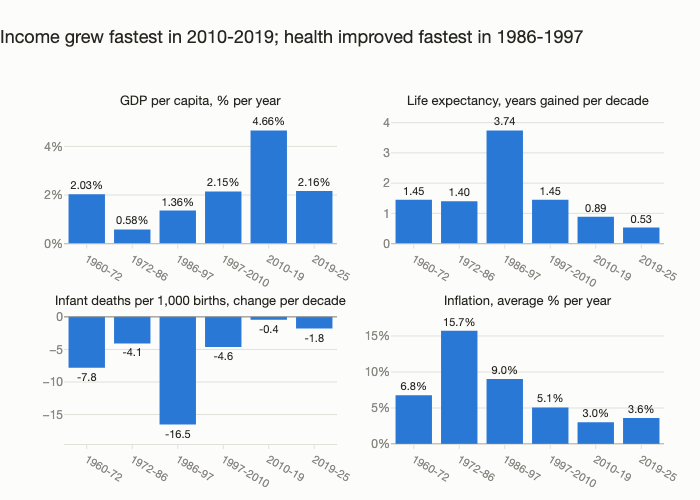

In [3]:
labels = [f"{s}-{str(e)[2:]}" if e < 2000 or s >= 2000 else f"{s}-{e}" for s, e, _ in ERAS]
panels = [
    ("gdp_rate_pct", "GDP per capita, % per year", "%{y:.2f}%", ".2f", "%"),
    ("le_per_decade", "Life expectancy, years gained per decade", "%{y:.2f} years", ".2f", ""),
    ("imr_per_decade", "Infant deaths per 1,000 births, change per decade", "%{y:.1f}", ".1f", ""),
    ("infl_mean", "Inflation, average % per year", "%{y:.1f}%", ".1f", "%"),
]

fig = make_subplots(rows=2, cols=2, subplot_titles=[p[1] for p in panels],
                    vertical_spacing=0.2, horizontal_spacing=0.09)
for i, (col, title, hover, fmt, suffix) in enumerate(panels):
    r, c = i // 2 + 1, i % 2 + 1
    fig.add_trace(go.Bar(
        x=labels, y=era[col].values, marker_color=BLUE, marker_line_width=0,
        text=[f"{v:{fmt}}{suffix}" for v in era[col].values],
        textposition="outside", textfont=dict(color=INK, size=11), cliponaxis=False,
        hovertemplate="%{x}: " + hover + "<extra></extra>"), row=r, col=c)
    fig.update_yaxes(ticksuffix=suffix, row=r, col=c)
    lo, hi = min(0, era[col].min()), max(0, era[col].max())
    pad = (hi - lo) * 0.18
    fig.update_yaxes(range=[lo - (pad if lo < 0 else 0), hi + (pad if hi > 0 else pad / 3)], row=r, col=c)
    fig.add_hline(y=0, line_color=MUTED, line_width=1, row=r, col=c)

for a in fig.layout.annotations:
    a.update(font=dict(size=13, color=INK), x=a.x, xanchor="center")
fig.update_xaxes(tickfont=dict(size=11, color=MUTED))
fig.update_layout(
    title="Income grew fastest in 2010-2019; health improved fastest in 1986-1997",
    hovermode="closest", margin=dict(t=110))
save(fig, "seg-01-eras", height=720)
fig.show()

### Observation
2010-2019 was the fastest income era, 4.66% a year, and the slowest health
era before COVID: lifespan rose 0.89 years per decade and infant mortality
barely moved, 23.0 to 22.6. 1986-1997 runs the other way. Income grew 1.36% a
year, yet lifespan rose 3.74 years per decade and infant mortality fell from
47.2 to 29.0, the fastest drop of any era. Inflation averaged 15.7% in
1972-1986, the highest of any era, with a 50.3% peak in 1984.

### Implication
Across eras, faster income growth and faster health gains did not line up.
Rank the eras by GDP and 2010-2019 comes first; rank them by lifespan or infant
survival and 1986-1997 comes first. This data cannot say why. Infant mortality
and life expectancy are modelled estimates that move smoothly from year to
year, so they cannot show a one-year shock the way GDP does.

## 2. Birth cohorts

Four Filipinos, born fifteen years apart: 1960, 1975, 1990, 2005. Each window
runs from the birth year to the year they turn 20, 21 annual readings. The 2005
cohort turns 20 in 2025, the last year in the data, so all four windows are
complete.

Life expectancy at birth is the period figure for the birth year: how long a
baby would live if that year's death rates held for life. It describes the
country the baby was born into. How long that cohort actually lives is a
different number, and this data does not hold it.

In [4]:
COHORTS = [1960, 1975, 1990, 2005]
COHORT_COLOR = dict(zip(COHORTS, [BLUE, ORANGE, AQUA, YELLOW]))

rows = []
for born in COHORTS:
    w = df.loc[born:born + 20]
    growth = df["gdp_growth_pct"].loc[born + 1:born + 20]
    gdp = w["gdp_per_capita_const"]
    rows.append(dict(
        born=born, turns_20=born + 20,
        gdp_birth=gdp.iloc[0], gdp_20=gdp.iloc[-1],
        gdp_change_pct=(gdp.iloc[-1] / gdp.iloc[0] - 1) * 100,
        le_birth=w["life_expectancy"].iloc[0],
        imr_birth=w["infant_mortality"].iloc[0],
        fertility_birth=w["fertility_rate"].iloc[0],
        infl_mean=w["inflation"].mean(),
        price_multiple=w["cpi_index_2024"].iloc[-1] / w["cpi_index_2024"].iloc[0],
        shrink_years=int((growth < 0).sum()),
        worst_year=growth.idxmin(), worst_growth=growth.min(),
    ))
cohort = pd.DataFrame(rows).set_index("born")

cohort_table = pd.DataFrame({
    "Turns 20": cohort.turns_20,
    "GDP per capita": [f"${a:,.0f} → ${b:,.0f}" for a, b in zip(cohort.gdp_birth, cohort.gdp_20)],
    "GDP change, birth to 20": cohort.gdp_change_pct.map("{:+.1f}%".format),
    "Life expectancy at birth": cohort.le_birth.map("{:.1f}".format),
    "Infant mortality at birth": cohort.imr_birth.map("{:.1f}".format),
    "Births per woman at birth": cohort.fertility_birth.map("{:.2f}".format),
    "Inflation avg, ages 0-20": cohort.infl_mean.map("{:.1f}%".format),
    "₱100 at birth costs, age 20": cohort.price_multiple.map(lambda v: f"₱{v * 100:,.0f}"),
    "Years GDP/cap shrank": cohort.shrink_years,
    "Weakest year": [f"{y}: {v:.2f}%" for y, v in zip(cohort.worst_year, cohort.worst_growth)],
}, index=cohort.index.rename("Born"))
cohort_table

,Turns 20,GDP per capita,"GDP change, birth to 20",Life expectancy at birth,Infant mortality at birth,Births per woman at birth,"Inflation avg, ages 0-20","₱100 at birth costs, age 20",Years GDP/cap shrank,Weakest year
Born,,,,,,,,,,
1960,1980,"$1,124 → $1,868",+66.2%,59.2,62.3,7.00,9.9%,₱661,0,1964: 0.24%
1975,1995,"$1,587 → $1,694",+6.7%,60.9,53.3,5.60,12.9%,"₱1,118",6,1984: -9.69%
1990,2010,"$1,704 → $2,373",+39.3%,64.4,38.8,4.32,6.8%,₱350,5,1998: -2.98%
2005,2025,"$2,038 → $4,066",+99.5%,68.4,25.0,3.45,3.8%,₱206,2,2020: -10.55%


`₱100 at birth costs, age 20` compounds the inflation series from the birth
year to age 20: what a basket priced at ₱100 in the birth year cost twenty
years later.

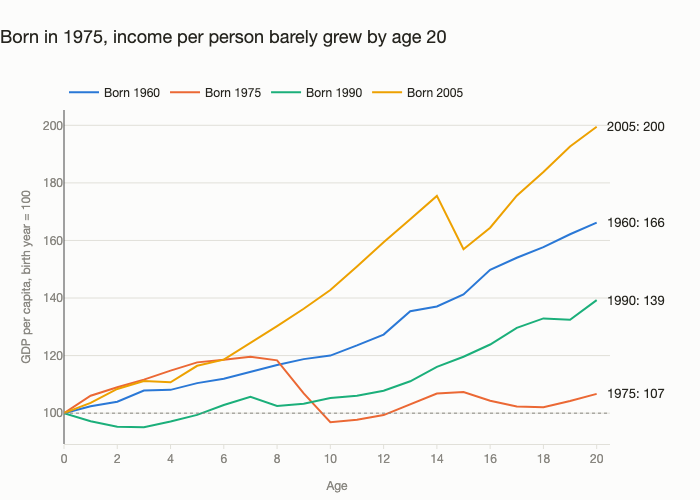

1975 cohort: peak 119.6 at age 7, low 96.9 at age 10, below birth level at ages [10, 11, 12]
1990 cohort below birth level at ages [1, 2, 3, 4, 5]
2005 cohort: age 14 175.5, age 15 157.0, first age back above age 14: 17


In [5]:
paths = {}
for born in COHORTS:
    gdp = df["gdp_per_capita_const"].loc[born:born + 20]
    paths[born] = pd.Series(gdp.values / gdp.iloc[0] * 100, index=range(len(gdp)), name=born)
paths = pd.DataFrame(paths)

fig = go.Figure()
for born in COHORTS:
    s = paths[born]
    fig.add_trace(go.Scatter(
        x=s.index, y=s.values, mode="lines", name=f"Born {born}",
        line=dict(color=COHORT_COLOR[born], width=2),
        customdata=list(range(born, born + 21)),
        hovertemplate=f"Born {born}, age %{{x}} (%{{customdata}}): %{{y:.1f}}<extra></extra>"))
    fig.add_annotation(x=20, y=s[20], text=f"{born}: {s[20]:.0f}", showarrow=False,
                       xanchor="left", xshift=8, font=dict(color=INK, size=13))
fig.add_hline(y=100, line_color=MUTED, line_width=1, line_dash="dot")

fig.update_layout(
    title="Born in 1975, income per person barely grew by age 20",
    xaxis_title="Age", yaxis_title="GDP per capita, birth year = 100",
    showlegend=True, hovermode="closest",
    legend=dict(orientation="h", x=0, y=1.01, xanchor="left", yanchor="bottom",
                font=dict(color=INK, size=12)),
    margin=dict(r=90, t=110), xaxis_range=[0, 20.5], xaxis_dtick=2)
save(fig, "seg-02-cohort-income")
fig.show()

i75 = paths[1975]
print(f"1975 cohort: peak {i75.max():.1f} at age {i75.idxmax()}, low {i75.min():.1f} at age {i75.idxmin()}, "
      f"below birth level at ages {list(i75[i75 < 100].index)}")
i90 = paths[1990]
print(f"1990 cohort below birth level at ages {list(i90[i90 < 100].index)}")
i05 = paths[2005]
print(f"2005 cohort: age 14 {i05[14]:.1f}, age 15 {i05[15]:.1f}, first age back above age 14: "
      f"{next(a for a in range(16, 21) if i05[a] > i05[14])}")

### Observation
Income per person rose every year of the 1960 cohort's childhood and ended
66.2% higher at age 20. The 1975 cohort peaked at age 7 (1982), fell to 96.9
by age 10, sat below the birth-year level from age 10 to 12, and turned 20 in
1995 only 6.7% richer than the year they were born. The 2005 cohort's income
per person nearly doubled, +99.5%, even with 2020's -10.55% at age 15; it
got back to its pre-COVID level at age 17.

### Implication
Birth year decided whose childhood ran through a crash. The 1975 cohort
reached adulthood in an economy that had barely grown in twenty years, with
six shrinking years along the way. The 2005 cohort lived through the worst
single year on record and still finished far ahead, because the years around
it grew fast.

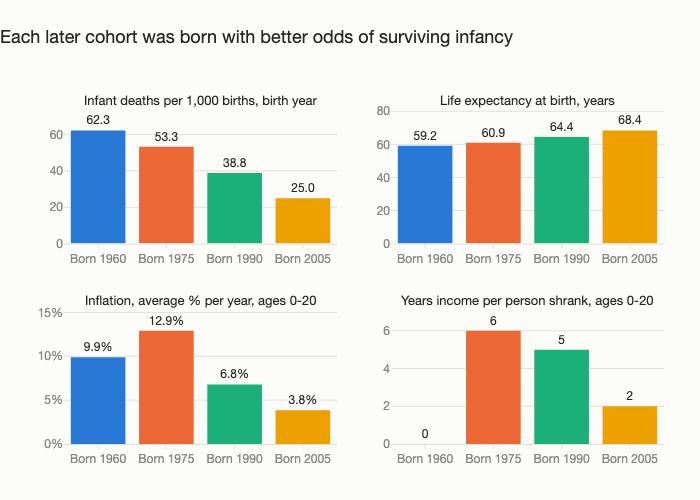

In [6]:
panels = [
    ("imr_birth", "Infant deaths per 1,000 births, birth year", ".1f", ""),
    ("le_birth", "Life expectancy at birth, years", ".1f", ""),
    ("infl_mean", "Inflation, average % per year, ages 0-20", ".1f", "%"),
    ("shrink_years", "Years income per person shrank, ages 0-20", "d", ""),
]
x = [f"Born {b}" for b in COHORTS]
colors = [COHORT_COLOR[b] for b in COHORTS]

fig = make_subplots(rows=2, cols=2, subplot_titles=[p[1] for p in panels],
                    vertical_spacing=0.2, horizontal_spacing=0.09)
for i, (col, title, fmt, suffix) in enumerate(panels):
    r, c = i // 2 + 1, i % 2 + 1
    vals = cohort[col].values
    fig.add_trace(go.Bar(
        x=x, y=vals, marker_color=colors, marker_line_width=0,
        text=[f"{v:{fmt}}{suffix}" for v in vals],
        textposition="outside", textfont=dict(color=INK, size=12), cliponaxis=False,
        hovertemplate="%{x}: %{text}<extra></extra>"), row=r, col=c)
    fig.update_yaxes(ticksuffix=suffix, range=[0, max(vals) * 1.18], row=r, col=c)

for a in fig.layout.annotations:
    a.update(font=dict(size=13, color=INK))
fig.update_layout(
    title="Each later cohort was born with better odds of surviving infancy",
    hovermode="closest", margin=dict(t=110))
save(fig, "seg-03-cohort-conditions", height=720)
fig.show()

### Observation
Infant mortality in the birth year fell from 62.3 per 1,000 for the 1960
cohort to 25.0 for the 2005 cohort, and life expectancy at birth rose from
59.2 to 68.4 years. Prices were a different story. The 1975 cohort's childhood
averaged 12.9% inflation, so ₱100 at birth cost ₱1,118 by age 20; for the
2005 cohort it cost ₱206.

### Implication
On health, each cohort was born into a better country than the one before,
with no exception among these four. On prices and income, the 1975 cohort did
worse than the one born fifteen years earlier. "Life got better" holds for
every cohort at birth; it does not hold for every childhood.

## 3. Peer countries

The first two cuts compare the Philippines with its own past. This one
compares it with four neighbours over the same years: Thailand, Vietnam,
Indonesia and Malaysia. All five were poor, mostly farming economies in 1960.
`docs/PEERS.md` explains the choice.

- **GDP per capita**: constant 2015 US$ on a log scale. Equal vertical
  distances mean equal percentage growth, and the levels stay readable, so the
  1960 gap stays in view.
- **Vietnam's GDP starts in 1984.** The World Bank has no earlier value. Its
  line starts in 1984 and its growth multiple runs from 1984. Nothing is
  rebased.
- **Life expectancy and infant mortality**: 1960 against 2024, the latest year
  for every country. Vietnam's infant mortality starts in 1964, so its start
  point is 1964.

In [7]:
peers = pd.read_csv(ROOT / "data" / "processed" / "peers.csv")
peers["country"] = peers["country"].replace({"Viet Nam": "Vietnam"})
PEERS = ["Philippines", "Malaysia", "Thailand", "Indonesia", "Vietnam"]
PEER_COLOR = dict(zip(PEERS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

def wide(col):
    return peers.pivot(index="year", columns="country", values=col)[PEERS]

gdp_peers = wide("gdp_per_capita_const")
ph = gdp_peers["Philippines"]
rank = gdp_peers.rank(axis=1, ascending=False)

# First year after which a peer stayed above the Philippines for good.
def passed_ph(c):
    above = (gdp_peers[c] > ph)[gdp_peers[c].notna()]
    below = above[~above]
    return None if above.all() else int(below.index.max() + 1)

rows = []
for c in PEERS:
    s = gdp_peers[c].dropna()
    y0, y1 = s.index[0], s.index[-1]
    rows.append({
        "Country": c, "First year": y0,
        "GDP per capita, first year": f"${s.iloc[0]:,.0f}",
        f"GDP per capita, {y1}": f"${s.iloc[-1]:,.0f}",
        "Multiple": f"{s.iloc[-1] / s.iloc[0]:.1f}x",
        "% per year": f"{((s.iloc[-1] / s.iloc[0]) ** (1 / (y1 - y0)) - 1) * 100:.1f}%",
        "Rank 1960": "-" if pd.isna(rank.loc[1960, c]) else int(rank.loc[1960, c]),
        f"Rank {y1}": int(rank.loc[y1, c]),
        "Passed the Philippines": "-" if c == "Philippines" else (passed_ph(c) or "always above"),
    })
peer_table = pd.DataFrame(rows).set_index("Country")

last_place = rank["Philippines"][rank["Philippines"] < 5].index.max() + 1
print(f"Philippines last of five every year from {last_place}")
peer_table

Philippines last of five every year from 2020


,First year,"GDP per capita, first year","GDP per capita, 2025",Multiple,% per year,Rank 1960,Rank 2025,Passed the Philippines
Country,,,,,,,,
Philippines,1960,"$1,124","$4,066",3.6x,2.0%,2,5,-
Malaysia,1960,"$1,266","$12,352",9.8x,3.6%,1,1,always above
Thailand,1960,$592,"$6,783",11.4x,3.8%,4,2,1984
Indonesia,1960,$598,"$4,555",7.6x,3.2%,3,3,1993
Vietnam,1984,$595,"$4,308",7.2x,4.9%,-,4,2020


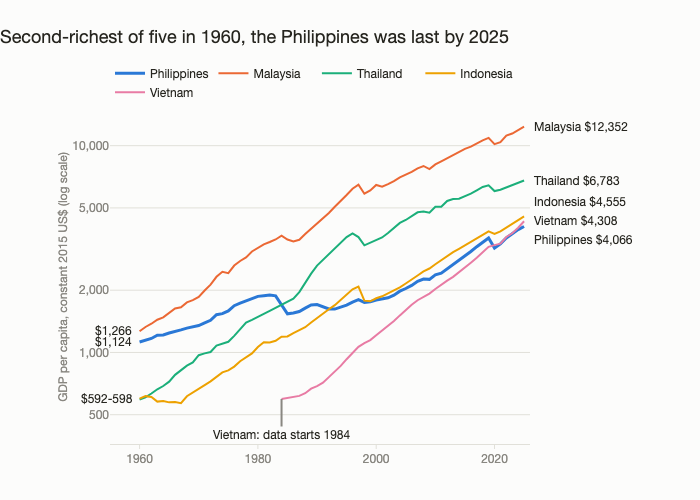

In [8]:
# On a log axis, annotation y is given in log10 units.
fig = go.Figure()
for c in PEERS:
    s = gdp_peers[c].dropna()
    fig.add_trace(go.Scatter(
        x=s.index, y=s.values, mode="lines", name=c,
        line=dict(color=PEER_COLOR[c], width=3 if c == "Philippines" else 2),
        hovertemplate=f"{c}, %{{x}}: $%{{y:,.0f}}<extra></extra>"))

# Indonesia, Vietnam and the Philippines end within $500 of each other, so
# their end labels are spread by hand.
END_SHIFT = {"Indonesia": 14, "Vietnam": 0, "Philippines": -14}
for c in PEERS:
    s = gdp_peers[c].dropna()
    fig.add_annotation(x=s.index[-1], y=np.log10(s.iloc[-1]), text=f"{c} ${s.iloc[-1]:,.0f}",
                       showarrow=False, xanchor="left", xshift=8,
                       yshift=END_SHIFT.get(c, 0), font=dict(color=INK, size=12))
# Thailand and Indonesia start $5 apart, so they share one label.
start_labels = {"Malaysia": "${:,.0f}", "Philippines": "${:,.0f}",
                "Thailand": "${:,.0f}-" + f"{gdp_peers.loc[1960, 'Indonesia']:,.0f}"}
for c, label in start_labels.items():
    fig.add_annotation(x=1960, y=np.log10(gdp_peers.loc[1960, c]),
                       text=label.format(gdp_peers.loc[1960, c]),
                       showarrow=False, xanchor="right", xshift=-6, font=dict(color=INK, size=12))
vn_start = gdp_peers["Vietnam"].first_valid_index()
fig.add_annotation(x=vn_start, y=np.log10(gdp_peers.loc[vn_start, "Vietnam"]),
                   text=f"Vietnam: data starts {vn_start}", showarrow=True, arrowhead=0,
                   arrowcolor=MUTED, ax=0, ay=36, font=dict(color=INK, size=12))

fig.update_layout(
    title="Second-richest of five in 1960, the Philippines was last by 2025",
    yaxis_title="GDP per capita, constant 2015 US$ (log scale)", xaxis_title=None,
    yaxis_type="log", yaxis_tickprefix="$", yaxis_tickformat=",",
    yaxis_tickvals=[500, 1000, 2000, 5000, 10000],
    showlegend=True, hovermode="closest",
    legend=dict(orientation="h", x=0, y=1.01, xanchor="left", yanchor="bottom",
                font=dict(color=INK, size=12)),
    margin=dict(l=110, r=170, t=110), xaxis_range=[1955, 2026])
save(fig, "seg-04-peer-income", height=600)
fig.show()

### Observation
In 1960 the Philippines had $1,124 of output per person, close to Malaysia's
$1,266 and 1.9 times Thailand's $592 and Indonesia's $598. By 2025 it had
$4,066, the lowest of the five: Malaysia $12,352, Thailand $6,783, Indonesia
$4,555, Vietnam $4,308. Thailand passed it for good in 1984, Indonesia in 1993
and Vietnam in 2020. Its 3.6x since 1960 is the smallest multiple of the five;
Thailand's is 11.4x, and Vietnam's is 7.2x from 1984 alone.

### Implication
The 1960 head start did not last. The 3.6x in `kpis.ipynb` is real growth, and
next to the neighbours it is the slowest. This chart shows when the gap
opened, not why. The five differ in size, politics, geography and shocks, and
none of that is in this table.

In [9]:
le_peers, imr_peers = wide("life_expectancy"), wide("infant_mortality")
END = 2024

def first_and_end(w):
    return pd.DataFrame({
        "start_year": [w[c].first_valid_index() for c in PEERS],
        "start": [w[c].dropna().iloc[0] for c in PEERS],
        "end": [w.loc[END, c] for c in PEERS],
    }, index=PEERS)

le_cmp, imr_cmp = first_and_end(le_peers), first_and_end(imr_peers)
le_cmp["gain"] = le_cmp["end"] - le_cmp["start"]
imr_cmp["fall_pct"] = (1 - imr_cmp["end"] / imr_cmp["start"]) * 100

health_table = pd.DataFrame({
    "Life expectancy": [f"{a:.1f} → {b:.1f}" for a, b in zip(le_cmp.start, le_cmp.end)],
    "Years gained": le_cmp.gain.map("{:+.1f}".format),
    f"Rank 1960 → {END}": [f"{int(a)} → {int(b)}" for a, b in zip(
        le_peers.loc[1960].rank(ascending=False), le_peers.loc[END].rank(ascending=False))],
    "Infant mortality": [f"{a:.1f} ({y}) → {b:.1f}" if y != 1960 else f"{a:.1f} → {b:.1f}"
                         for a, b, y in zip(imr_cmp.start, imr_cmp.end, imr_cmp.start_year)],
    "Fall": imr_cmp.fall_pct.map("{:.0f}%".format),
}, index=pd.Index(PEERS, name="Country"))
health_table

,Life expectancy,Years gained,Rank 1960 → 2024,Infant mortality,Fall
Country,,,,,
Philippines,59.2 → 69.9,+10.8,1 → 5,62.3 → 21.7,65%
Malaysia,57.2 → 76.8,+19.7,3 → 1,68.3 → 7.0,90%
Thailand,50.6 → 76.6,+26.0,4 → 2,113.3 → 7.7,93%
Indonesia,46.8 → 71.3,+24.5,5 → 4,146.7 → 15.2,90%
Vietnam,58.0 → 74.7,+16.7,2 → 3,60.8 (1964) → 12.0,80%


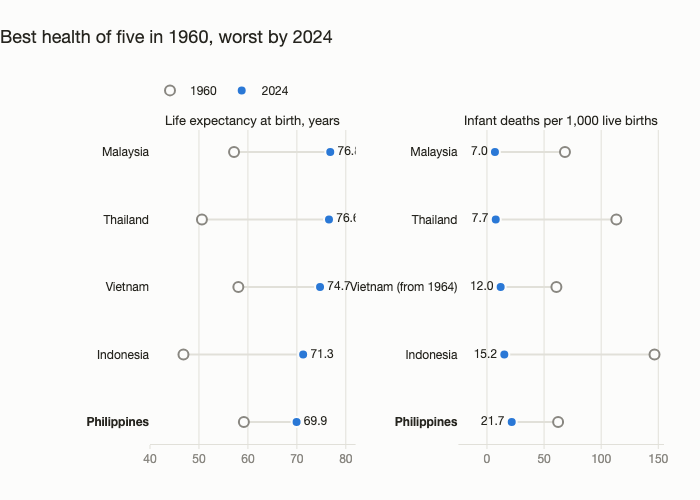

In [10]:
panels = [
    (le_cmp, "Life expectancy at birth, years", "{:.1f}", False),
    (imr_cmp, "Infant deaths per 1,000 live births", "{:.1f}", True),
]
fig = make_subplots(rows=1, cols=2, subplot_titles=[p[1] for p in panels],
                    horizontal_spacing=0.2)
for i, (cmp, title, fmt, lower_better) in enumerate(panels, start=1):
    order = cmp.sort_values("end", ascending=lower_better).index[::-1]
    names = [f"<b>{c}</b>" if c == "Philippines" else
             (f"{c} (from {cmp.start_year[c]})" if cmp.start_year[c] != 1960 else c)
             for c in order]
    for c, n in zip(order, names):
        fig.add_trace(go.Scatter(
            x=[cmp.start[c], cmp.end[c]], y=[n, n], mode="lines",
            line=dict(color=GRID, width=2), hoverinfo="skip", showlegend=False),
            row=1, col=i)
    fig.add_trace(go.Scatter(
        x=cmp.start[order], y=names, mode="markers", name="1960",
        marker=dict(color=SURFACE, size=10, line=dict(color=MUTED, width=2)),
        customdata=cmp.start_year[order],
        hovertemplate="%{y}, %{customdata}: %{x:.1f}<extra></extra>",
        showlegend=i == 1), row=1, col=i)
    fig.add_trace(go.Scatter(
        x=cmp.end[order], y=names, mode="markers+text", name=str(END),
        marker=dict(color=BLUE, size=10, line=dict(color=SURFACE, width=2)),
        text=[fmt.format(v) for v in cmp.end[order]],
        textposition="middle left" if lower_better else "middle right",
        textfont=dict(color=INK, size=12),
        hovertemplate=f"%{{y}}, {END}: %{{x:.1f}}<extra></extra>",
        showlegend=i == 1), row=1, col=i)

fig.update_xaxes(range=[40, 82], row=1, col=1)
fig.update_xaxes(range=[-25, 155], row=1, col=2)
fig.update_yaxes(showgrid=False, tickfont=dict(color=INK, size=12))
fig.update_xaxes(showgrid=True, gridcolor=GRID, zeroline=False)
for a in fig.layout.annotations:
    a.update(font=dict(size=13, color=INK))
fig.update_layout(
    title="Best health of five in 1960, worst by 2024",
    showlegend=True, hovermode="closest",
    legend=dict(orientation="h", x=0, y=1.08, xanchor="left", yanchor="bottom",
                font=dict(color=INK, size=12)),
    margin=dict(l=150, t=130))
save(fig, "seg-05-peer-health", height=480)
fig.show()

### Observation
In 1960 the Philippines had the longest life expectancy of the five, 59.2
years, and the lowest infant mortality of the four measured that year, 62.3
per 1,000 births. By 2024 it had the shortest life expectancy, 69.9 years,
against 76.8 in Malaysia and 76.6 in Thailand, and the highest infant
mortality, 21.7 against 7.0 in Malaysia and 7.7 in Thailand. It gained 10.8
years of life expectancy; every neighbour gained more, from 16.7 in Vietnam to
26.0 in Thailand.

### Implication
Health tells the same story as income. On its own, 1960 to 2024 reads as
progress for the Philippines, and it was. Next to four neighbours that started
in the same region and the same poverty, the Philippines went from first to
last on both health measures. As with income, this shows the gap, not its
cause.

## What segmentation shows

Gains landed in different places depending on the measure. Income per person
grew fastest in 2010-2019. Lifespan and infant survival improved fastest in
1986-1997, a slow-growth era. Across these six eras the two sets of measures
did not move together.

By birth cohort, every later cohort started life with lower infant mortality
and a longer life expectancy at birth. Childhood income did not follow the
same order: the 1975 cohort had six shrinking years and ended at age 20 only
6.7% above where it started.

Against its neighbours, the Philippines fell from near the top to the bottom.
It was second of five on income per person in 1960 and first on life
expectancy; by 2025 it was last on income, and by 2024 last on life
expectancy and infant mortality. Every measure improved at home, and every
neighbour improved faster.

All of this is association. The era names mark who governed or what happened,
and the numbers show what changed during those years; they do not show that
any government or event made the change. The same holds for the peer gap:
the data shows that it opened, not what opened it. Era rates also depend on
their endpoints: 1972-1986 ends one year after the 1985 low in income per
person, and a boundary one year either way gives a different rate. Every
figure is a national average, so none of it says how a given household
fared.